In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def mostrar(imagens, titulos, cmaps=[], tamanho=4):
  n = len(imagens)
  plt.figure(figsize=(tamanho*n, tamanho))
  for i in range(n):
    if len(cmaps) <= i:
      cmaps.append('gray')
    elif cmaps[i] == None or cmaps[i] == '':
      cmaps[i] = 'gray'

    plt.subplot(1, n, i+1)
    plt.imshow(imagens[i], cmap=cmaps[i])
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()

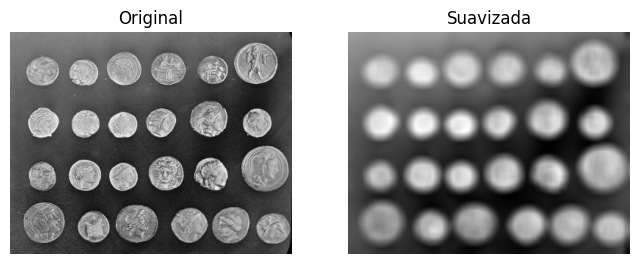

In [3]:
moedas = data.coins()
moedas_suave = cv2.GaussianBlur(moedas, (15,15), 10)
mostrar([moedas, moedas_suave], ['Original', 'Suavizada'])

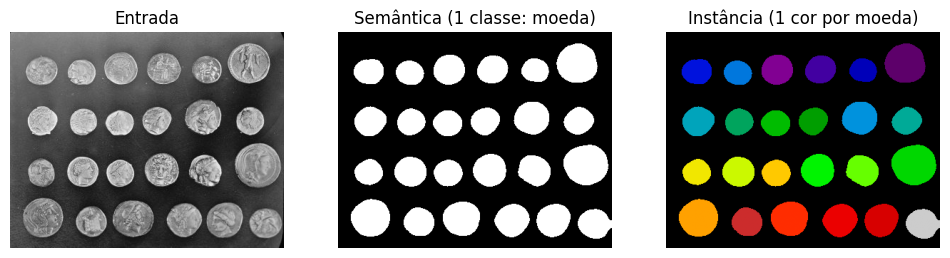

In [4]:
moedas_sem = cv2.adaptiveThreshold(
    moedas_suave,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    151,
    -12
)

_, moedas_inst = cv2.connectedComponents(moedas_sem)

mostrar(
  [moedas, moedas_sem, moedas_inst],
  ['Entrada', 'Semântica (1 classe: moeda)', 'Instância (1 cor por moeda)'],
  ['gray', 'gray', 'nipy_spectral']
)

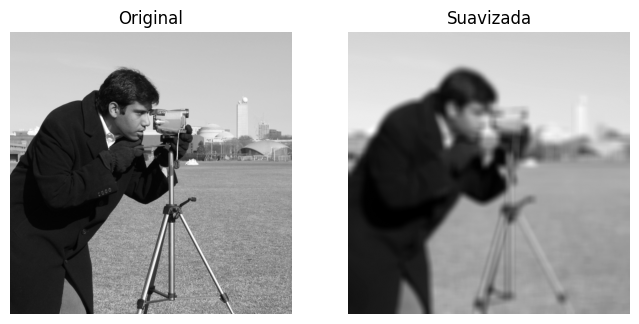

In [5]:
camera = data.camera()
camera_suave = cv2.GaussianBlur(camera, (15,15), 10)
mostrar([camera, camera_suave], ['Original', 'Suavizada'])

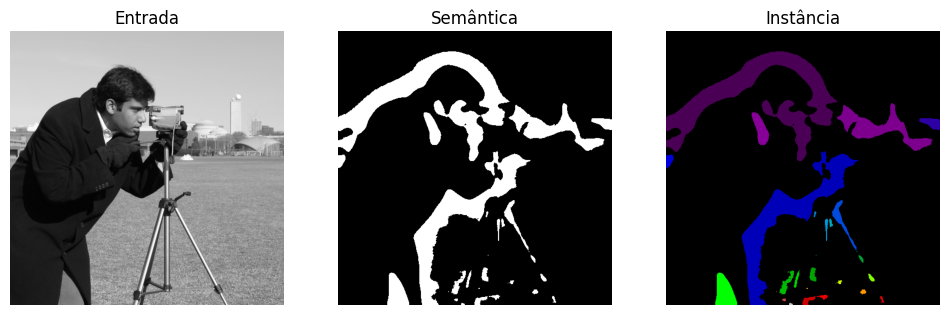

In [6]:
camera_sem = cv2.adaptiveThreshold(
    camera_suave,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    151,
    -12
)

_, camera_inst = cv2.connectedComponents(camera_sem)

mostrar(
  [camera, camera_sem, camera_inst],
  ['Entrada', 'Semântica', 'Instância'],
  ['gray', 'gray', 'nipy_spectral']
)

Houve diferença entre as duas imagens. data.coins() tem iluminação bem-distribuída e moedas claramente separadas, enquanto data.camera() está em um ambiente natural e os objetos se sobrepõem em diversos pontos.